# Greedy stitching scratch

Each example is a list of `(left, right)` tuples sorted by `left`.
Bounds are site indexes; `right` is exclusive. Each row represents a different
candidate ancestor, including rows with identical bounds.

All examples use the same site domain `[0, num_sites)`. The minimum focal
region size applies to a connected union of intervals, including touching
intervals. It does not filter individual ancestors.

The plots show only the input intervals. Use the empty cells to explore your
own copying paths, gaps and treatment of short connected regions.

In [2]:
import pathlib

from ch5 import nb_plot, nb_utils

repository_dir = pathlib.Path.cwd()
config = {
    "num_sites": 40,
    "min_focal_region": 10,
    "figure_width": 10,
    "row_height": 0.45,
    "minimum_figure_height": 2.4,
    "tick_step": 5,
}

## 1. Overlapping chain across the whole domain

Start with a connected example whose coverage reaches both domain boundaries.

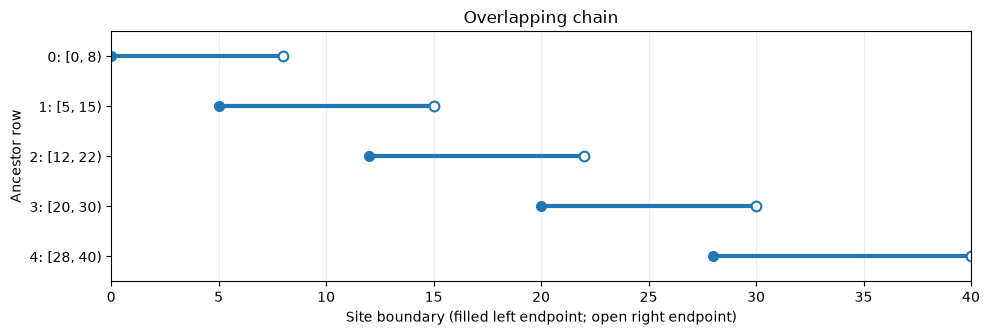

In [3]:
intervals_chain = [(0, 8), (5, 15), (12, 22), (20, 30), (28, 40)]
nb_plot.plot_intervals(
    intervals_chain,
    "Overlapping chain",
    config=config,
    plot_figure_width=10,
    plot_minimum_figure_height=2.4,
    plot_row_height=0.45,
    plot_tick_step=5,
)

In [93]:
# Save the last region if it satisfies criteria
# Update parent
# Better starting parent
# Update region bounds
nb_utils.make_focal_regions_buffered(intervals_chain)

Processing 0
Starting region at 0
Starting parent is 0 from 0 to 8
Processing 1
New next_parent is 1 ending at 15
Processing 2
Moved past current parent 0 which ends at 8, now at 12
Longest parent now is 1 ending at 14
New next_parent is 2 ending at 22
Processing 3
Moved past current parent 1 which ends at 15, now at 20
Longest parent now is 2 ending at 21
New next_parent is 3 ending at 30
Processing 4
Moved past current parent 2 which ends at 22, now at 28
Longest parent now is 3 ending at 29
New next_parent is 4 ending at 40
After last int, we have current (22,30): 3
New next parent is 4 ending at 40


([(0, 40)],
 [((0, 8), 0), ((8, 15), 1), ((15, 22), 2), ((22, 30), 3), ((30, 40), 4)])

In [103]:
# attempt 2
# Outer loop (1) only advances when a focal region finishes
# Middle loop (2): moves cursor forward through the region
# Inner loop (3): for fixed cursor, find parent with longest reach
# Exit loop 3 - either no parent or found the best
# Exit Loop 2 because we have hit a gap
# Move cursor forward to where the next path starts
# Still inside outer loop: decide whether to retain this region.
# Outer loop repeats as long as there are intervals untouched

## 2. Containment and ties

Consider equal left endpoints, equal right endpoints, contained intervals and
duplicate bounds. The row index can serve as the ancestor identity.

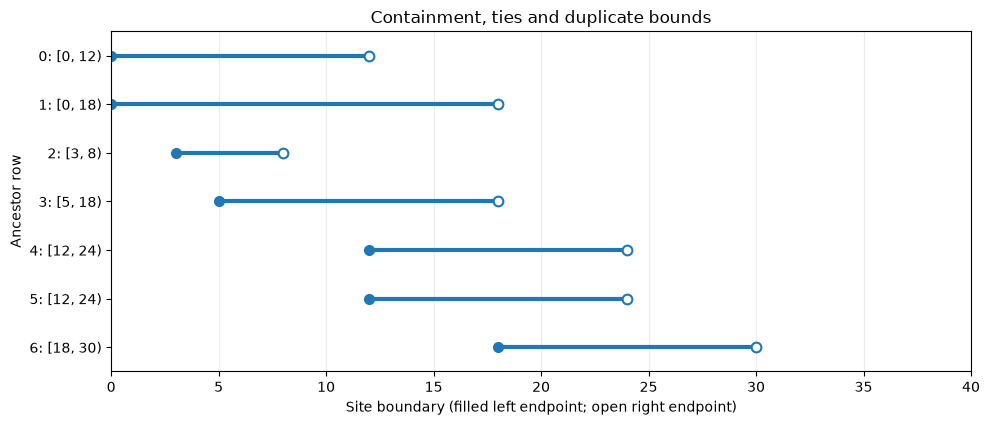

In [101]:
intervals_nested = [(0, 12), (0, 18), (3, 8), (5, 18), (12, 24), (12, 24), (18, 30)]
nb_plot.plot_intervals(
    intervals_nested,
    "Containment, ties and duplicate bounds",
    config=config,
    plot_figure_width=10,
    plot_minimum_figure_height=2.4,
    plot_row_height=0.45,
    plot_tick_step=5,
)

In [104]:
nb_utils.make_focal_regions(intervals_nested, min_width=1)

([(0, 30)], [((0, 18), 1), ((18, 30), 6)])

## 3. Touching endpoints and a one-site gap

Pay attention to the exclusive right endpoints when deciding where there is
continuous coverage and where a gap begins.

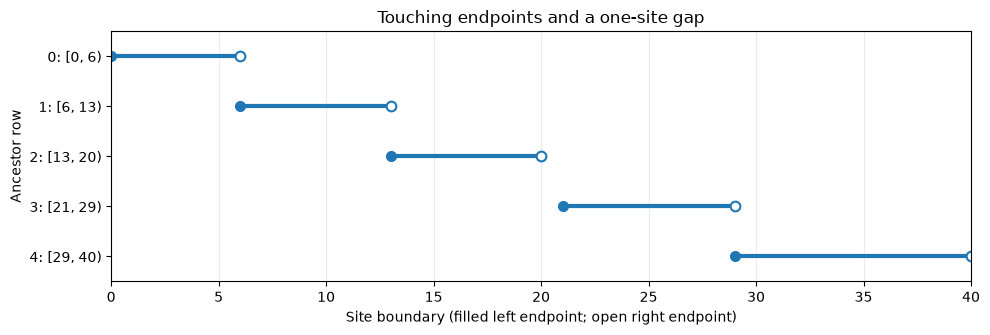

In [105]:
intervals_touching = [(0, 6), (6, 13), (13, 20), (21, 29), (29, 40)]
nb_plot.plot_intervals(
    intervals_touching,
    "Touching endpoints and a one-site gap",
    config=config,
    plot_figure_width=10,
    plot_minimum_figure_height=2.4,
    plot_row_height=0.45,
    plot_tick_step=5,
)

In [107]:
nb_utils.make_focal_regions(intervals_touching, min_width=1)

([(0, 20), (21, 40)],
 [((0, 6), 0), ((6, 13), 1), ((13, 20), 2), ((21, 29), 3), ((29, 40), 4)])

## 4. Multiple components and boundary gaps

Include the beginning and end of the domain when recording gaps. Apply the
minimum focal-region size to each connected component.

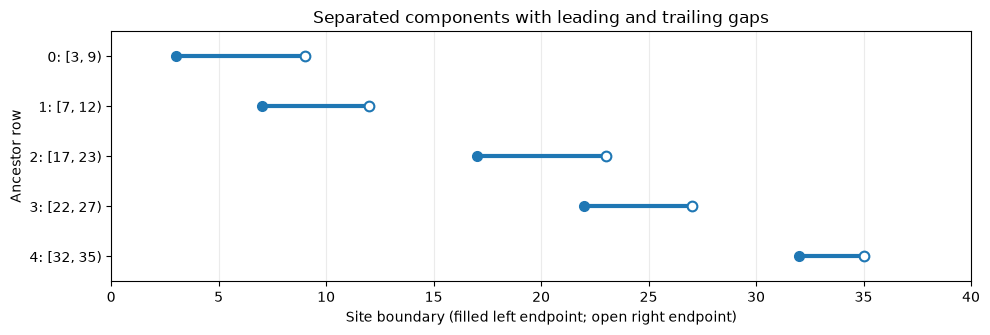

In [108]:
intervals_gaps = [(3, 9), (7, 12), (17, 23), (22, 27), (32, 35)]
nb_plot.plot_intervals(
    intervals_gaps,
    "Separated components with leading and trailing gaps",
    config=config,
    plot_figure_width=10,
    plot_minimum_figure_height=2.4,
    plot_row_height=0.45,
    plot_tick_step=5,
)

In [110]:
nb_utils.make_focal_regions(intervals_gaps, min_width=10)

([(17, 27)], [((17, 23), 2), ((23, 27), 3)])

## 5. Total length and remaining reach

Revisit the choice available after reaching site 8. You can first explore the
covering choices without minimum-size filtering, then apply the configured
minimum to the connected region.

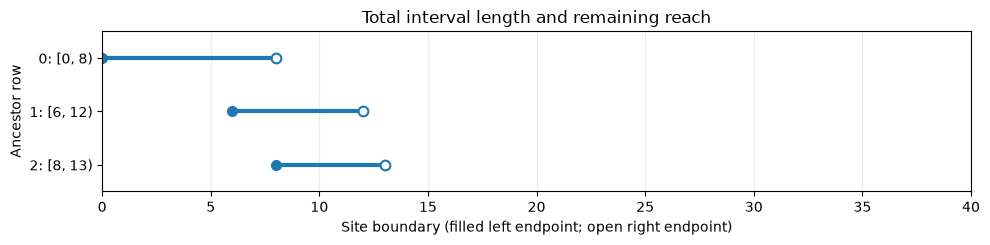

In [111]:
intervals_reach = [(0, 8), (6, 12), (8, 13)]
nb_plot.plot_intervals(
    intervals_reach,
    "Total interval length and remaining reach",
    config=config,
    plot_figure_width=10,
    plot_minimum_figure_height=2.4,
    plot_row_height=0.45,
    plot_tick_step=5,
)

In [112]:
nb_utils.make_focal_regions(intervals_reach, min_width=1)

([(0, 13)], [((0, 8), 0), ((8, 13), 2)])

## 6. Connected regions around the minimum

These components span one site below, exactly at, and one site above the
configured minimum of ten sites. Every individual interval is shorter than
that minimum. Check the equality case and how discarded regions affect gaps.

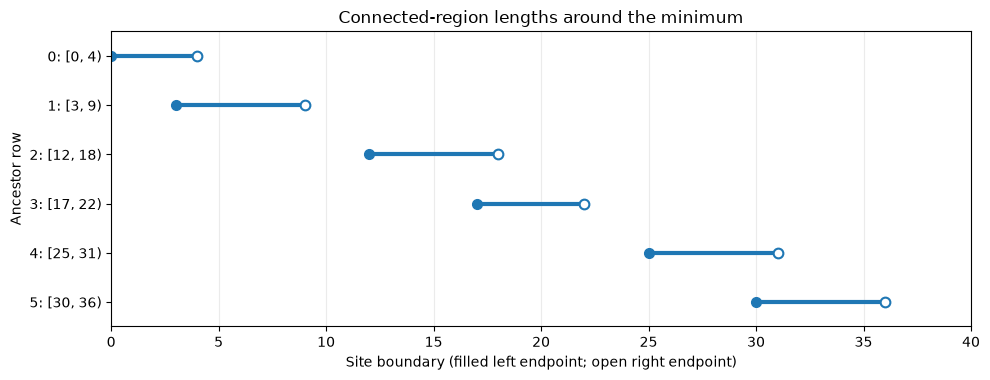

In [113]:
intervals_minimum = [(0, 4), (3, 9), (12, 18), (17, 22), (25, 31), (30, 36)]
nb_plot.plot_intervals(
    intervals_minimum,
    "Connected-region lengths around the minimum",
    config=config,
    plot_figure_width=10,
    plot_minimum_figure_height=2.4,
    plot_row_height=0.45,
    plot_tick_step=5,
)

In [114]:
nb_utils.make_focal_regions(intervals_minimum, min_width=11)

([(25, 36)], [((25, 31), 4), ((31, 36), 5)])

## 7. No focal candidates

Consider what the output should contain over the full domain.

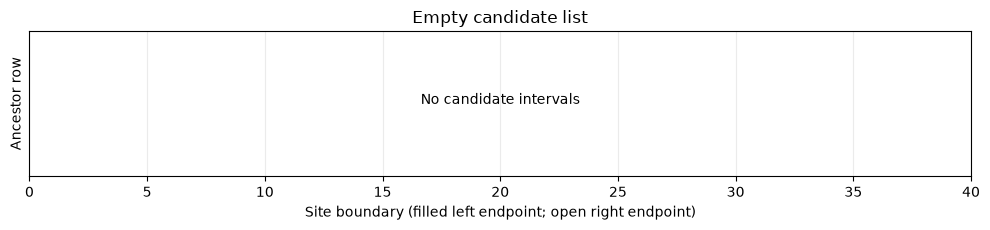

In [115]:
intervals_empty = []
nb_plot.plot_intervals(
    intervals_empty,
    "Empty candidate list",
    config=config,
    plot_figure_width=10,
    plot_minimum_figure_height=2.4,
    plot_row_height=0.45,
    plot_tick_step=5,
)

In [116]:
nb_utils.make_focal_regions(intervals_empty, min_width=11)

([], [])